In [1]:
# Step 1: Import pandas to work with tables and calculate answers.
import pandas as pd

# Step 2: Import matplotlib to create the required bar chart.
import matplotlib.pyplot as plt

# Step 3: Import Path to locate the CSV file in the same folder as the notebook.
from pathlib import Path

In [2]:
# Step 4: Specify the CSV filename supplied with this notebook.
file_path = Path(r"C:\Users\dell\Downloads\student_tea_snacks _1_.csv")

# Step 5: Also support the original uploaded filename, if you use that instead.
if not file_path.exists():
    file_path = Path("student_tea_snacks _1_.csv")

# Step 6: Read the CSV into a pandas DataFrame (table).
df = pd.read_csv(file_path)

# Step 7: Show the first five rows and total number of students.
print("First five rows of the dataset:")
print(df.head().to_string(index=False))
print(f"\nTotal students: {len(df)}")
print("\nMissing entries in each column:")
print(df.isna().sum().to_string())

First five rows of the dataset:
student_id gender age_group prefers_tea    tea_type snack_choice  cups_per_day
      S001   Male     21-23          No       Black       Samosa             2
      S002   Male     21-23          No       Green       Samosa             3
      S003   Male     18-20          No Doodh Patti      Biscuit             0
      S004   Male     21-23         Yes         NaN       Samosa             1
      S005   Male     18-20         Yes       Green       Samosa             4

Total students: 100

Missing entries in each column:
student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0


In [3]:
# Step 8: Count how many times each tea type appears.
# value_counts() automatically leaves out missing/blank tea type values.
tea_counts = df["tea_type"].value_counts()

# Step 9: Find the tea type with the highest number of students.
most_preferred_tea = tea_counts.idxmax()
max_tea_count = tea_counts.max()

# Step 10: Print the counts and clearly state the answer.
print("Q1: Tea preference counts:")
print(tea_counts.to_string())
print(f"\nAnswer: {most_preferred_tea} is the most preferred tea type ({max_tea_count} students).")
print(f"Missing tea type entries: {df['tea_type'].isna().sum()}")

Q1: Tea preference counts:
tea_type
Green          29
Doodh Patti    25
Black          23

Answer: Green is the most preferred tea type (29 students).
Missing tea type entries: 23


In [4]:
# Step 11: Group students by gender and calculate mean cups per day.
avg_cups_by_gender = df.groupby("gender")["cups_per_day"].mean()

# Step 12: Round the results to two decimal places when displaying them.
print("Q2: Average cups per day by gender:")
print(avg_cups_by_gender.round(2).to_string())

# Step 13: Find which gender has the higher average.
print(f"\nAnswer: {avg_cups_by_gender.idxmax()} has the higher average ")
print(f"({avg_cups_by_gender.max():.2f} cups per day).")

Q2: Average cups per day by gender:
gender
Female    2.6
Male      3.0

Answer: Male has the higher average 
(3.00 cups per day).


Q3: Snack choices:
snack_choice
Samosa     40
Chips      31
Biscuit    29


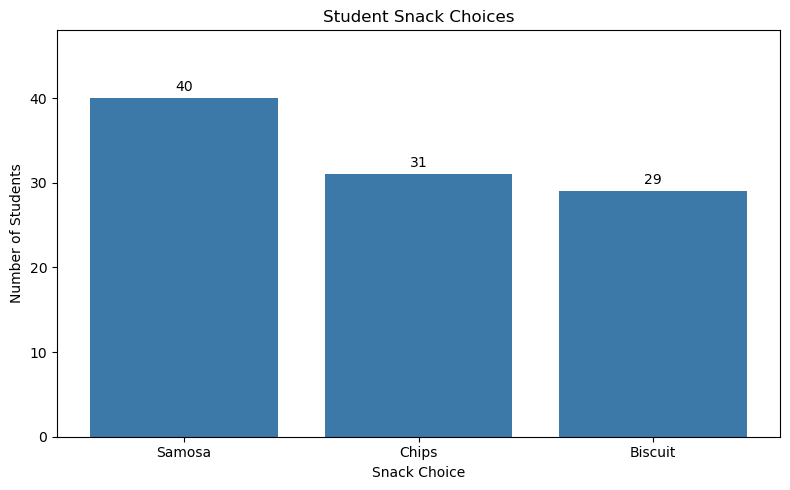

Answer: Samosa is the most popular snack (40 students).


In [5]:
# Step 14: Count how many students chose each snack.
snack_counts = df["snack_choice"].value_counts()
print("Q3: Snack choices:")
print(snack_counts.to_string())

# Step 15: Create a bar chart using the calculated snack counts.
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(snack_counts.index, snack_counts.values, color="#3C78A8")

# Step 16: Add chart title, axis labels, and the exact counts above each bar.
ax.set_title("Student Snack Choices")
ax.set_xlabel("Snack Choice")
ax.set_ylabel("Number of Students")
ax.bar_label(bars, padding=3)
ax.set_ylim(0, snack_counts.max() + 8)

# Step 17: Adjust spacing and display the bar chart.
fig.tight_layout()
plt.show()
print(f"Answer: {snack_counts.idxmax()} is the most popular snack ({snack_counts.max()} students).")

In [6]:
# Step 18: Make a table showing Yes/No tea preference for each age group.
# A crosstab counts students in each combination of two categories.
age_tea_counts = pd.crosstab(df["age_group"], df["prefers_tea"])

# Step 19: Reorder the age groups and Yes/No columns for easy comparison.
age_tea_counts = age_tea_counts.reindex(index=["18-20", "21-23", "24-26"], columns=["Yes", "No"], fill_value=0)

# Step 20: Convert the counts to percentages within each age group.
age_tea_percentages = age_tea_counts.div(age_tea_counts.sum(axis=1), axis=0) * 100

# Step 21: Display both the actual student counts and percentages.
print("Q4: Tea preference (number of students) by age group:")
print(age_tea_counts.to_string())
print("\nTea preference (percentage within each age group):")
print(age_tea_percentages.round(1).to_string())

# Step 22: Identify the age group with the highest percentage choosing Yes.
top_age_group = age_tea_percentages["Yes"].idxmax()
print(f"\nAnswer: Ages {top_age_group} have the highest Yes percentage ")
print(f"({age_tea_percentages.loc[top_age_group, 'Yes']:.1f}%).")

Q4: Tea preference (number of students) by age group:
prefers_tea  Yes  No
age_group           
18-20         20  19
21-23         15  17
24-26         16  13

Tea preference (percentage within each age group):
prefers_tea   Yes    No
age_group              
18-20        51.3  48.7
21-23        46.9  53.1
24-26        55.2  44.8

Answer: Ages 24-26 have the highest Yes percentage 
(55.2%).


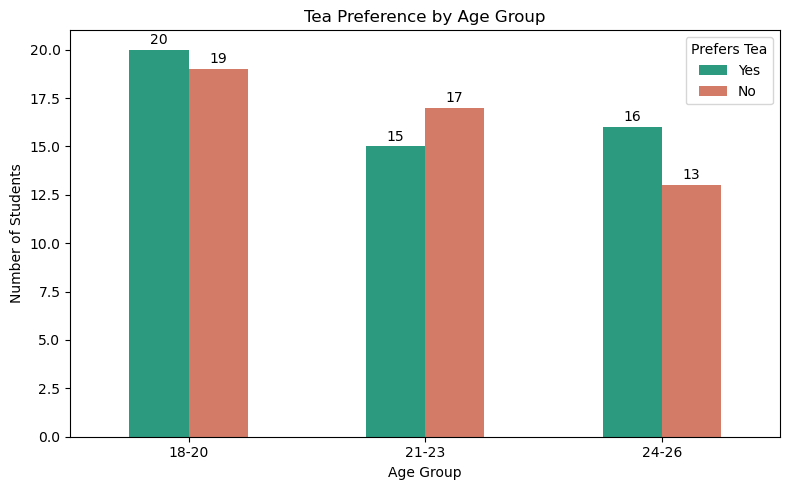

In [7]:
# Step 23: Create a grouped bar chart to compare Yes and No responses by age group.
ax = age_tea_counts.plot(kind="bar", figsize=(8, 5), color=["#2B9A7E", "#D47B68"], rot=0)

# Step 24: Add a title, axis labels, legend, and student counts.
ax.set_title("Tea Preference by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Number of Students")
ax.legend(title="Prefers Tea")
for bars in ax.containers:
    ax.bar_label(bars, padding=2)

# Step 25: Adjust spacing and show the comparison chart.
plt.tight_layout()
plt.show()

In [8]:
# Step 26: Count Black, Doodh Patti, and Green tea types for each age group.
# Missing tea types are excluded because there is no recorded type to compare.
tea_types_by_age = pd.crosstab(df["age_group"], df["tea_type"])
tea_types_by_age = tea_types_by_age.reindex(index=["18-20", "21-23", "24-26"], fill_value=0)

# Step 27: Print the table and the most common recorded tea type per age group.
print("Q4 (extra): Tea type counts by age group:")
print(tea_types_by_age.to_string())
print("\nMost common recorded tea type in each age group:")
print(tea_types_by_age.idxmax(axis=1).to_string())

Q4 (extra): Tea type counts by age group:
tea_type   Black  Doodh Patti  Green
age_group                           
18-20          9           11     13
21-23          9            6      5
24-26          5            8     11

Most common recorded tea type in each age group:
age_group
18-20    Green
21-23    Black
24-26    Green


In [9]:
# Step 28: Use the prefers_tea column to count students who answered No.
non_tea_students = df["prefers_tea"].eq("No").sum()

# Step 29: Display the result.
print(f"Q5 Answer: {non_tea_students} students selected 'No' for tea preference.")

Q5 Answer: 49 students selected 'No' for tea preference.
